In [1]:

# Cell 1 - Environment and Dataset Verification

from pathlib import Path
import sys
import pandas as pd
import numpy as np
import sklearn

print("CUSTOMER TRANSACTION PREDICTION")
print("=" * 60)

print("Python version:", sys.version.split()[0])
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Scikit-learn version:", sklearn.__version__)

print("\nCURRENT PROJECT FOLDER")
print("=" * 60)
print(Path.cwd())

print("\nDATASET FILES")
print("=" * 60)

dataset_files = [
    file for file in Path.cwd().iterdir()
    if file.suffix.lower() in [".csv", ".xlsx", ".zip"]
]

if dataset_files:
    for file in sorted(dataset_files):
        size_mb = file.stat().st_size / (1024 ** 2)
        print(f"{file.name} - {size_mb:.2f} MB")
else:
    print("No dataset files found.")


CUSTOMER TRANSACTION PREDICTION
Python version: 3.14.3
Pandas version: 3.0.3
NumPy version: 2.4.2
Scikit-learn version: 1.9.0

CURRENT PROJECT FOLDER
E:\datamites project\Hardest capstone 4\Tansaction\Customer transcation Pediction

DATASET FILES
Train.csv - 288.14 MB


In [2]:

# Cell 2 - Load Customer Transaction Dataset

import pandas as pd

# Step 1: Identify column names without loading all rows
dataset_path = "Train.csv"

column_names = pd.read_csv(
    dataset_path,
    nrows=0
).columns.tolist()

# Step 2: Identify the numerical feature columns
feature_columns = [
    col for col in column_names
    if col not in ["ID_code", "target"]
]

# Step 3: Set memory-efficient data types
dtype_mapping = {
    col: "float32"
    for col in feature_columns
}

dtype_mapping["target"] = "int8"

# Step 4: Load the complete dataset
df = pd.read_csv(
    dataset_path,
    dtype=dtype_mapping
)

print("DATASET LOADED SUCCESSFULLY")
print("=" * 60)

# Step 5: Check the shape
print("Dataset shape:", df.shape)
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

# Step 6: Check important columns
print("\nCOLUMN INFORMATION")
print("=" * 60)

print("Numerical feature columns:", len(feature_columns))
print("ID_code available:", "ID_code" in df.columns)
print("Target available:", "target" in df.columns)

# Step 7: Display selected columns
print("\nFIRST 5 ROWS")
print("=" * 60)

preview_columns = (
    ["ID_code"] +
    feature_columns[:5] +
    ["target"]
)

display(df[preview_columns].head())

# Step 8: Check memory usage
memory_mb = (
    df.memory_usage(deep=True).sum() / (1024 ** 2)
)

print("\nDATASET MEMORY USAGE")
print("=" * 60)

print(f"Memory usage: {memory_mb:.2f} MB")


DATASET LOADED SUCCESSFULLY
Dataset shape: (200000, 202)
Total rows: 200000
Total columns: 202

COLUMN INFORMATION
Numerical feature columns: 200
ID_code available: True
Target available: True

FIRST 5 ROWS


,ID_code,var_0,var_1,var_2,var_3,var_4,target
0,train_0,8.9255,-6.7863,11.9081,5.0930,11.4607,0
1,train_1,11.5006,-4.1473,13.8588,5.3890,12.3622,0
2,train_2,8.6093,-2.7457,12.0805,7.8928,10.5825,0
3,train_3,11.0604,-2.1518,8.9522,7.1957,12.5846,0
4,train_4,9.8369,-1.4834,12.8746,6.6375,12.2772,0



DATASET MEMORY USAGE
Memory usage: 164.31 MB


In [3]:

# Cell 3 - Dataset Quality and Target Distribution

print("DATASET QUALITY ASSESSMENT")
print("=" * 60)

# Step 1: Missing values
missing_values = df.isnull().sum()

print("\nMISSING VALUE ANALYSIS")
print("=" * 60)

print("Total missing values:", missing_values.sum())
print("Columns with missing values:", (missing_values > 0).sum())

# Step 2: Duplicate records
print("\nDUPLICATE RECORD ANALYSIS")
print("=" * 60)

print("Duplicate full rows:", df.duplicated().sum())

print(
    "Duplicate customer IDs:",
    df["ID_code"].duplicated().sum()
)

print(
    "Duplicate feature rows:",
    df[feature_columns].duplicated().sum()
)

# Step 3: Target distribution
print("\nTARGET CLASS DISTRIBUTION")
print("=" * 60)

target_counts = df["target"].value_counts().sort_index()

target_percentages = (
    df["target"].value_counts(normalize=True)
    .sort_index() * 100
)

target_distribution = pd.DataFrame({
    "Count": target_counts,
    "Percentage (%)": target_percentages
})

display(target_distribution.round(2))

# Step 4: Target validation
print("\nTARGET VALIDATION")
print("=" * 60)

print("Unique target values:", sorted(df["target"].unique()))
print("Target data type:", df["target"].dtype)

# Step 5: Feature data types
print("\nFEATURE DATA TYPES")
print("=" * 60)

display(
    df[feature_columns]
    .dtypes
    .value_counts()
    .rename_axis("Data Type")
    .reset_index(name="Feature Count")
)

# Step 6: Basic integrity checks
assert df["ID_code"].is_unique, "Duplicate customer IDs found"
assert df["target"].dropna().isin([0, 1]).all(), "Invalid target values"

print("\nBasic dataset integrity checks: PASSED")


DATASET QUALITY ASSESSMENT

MISSING VALUE ANALYSIS
Total missing values: 0
Columns with missing values: 0

DUPLICATE RECORD ANALYSIS
Duplicate full rows: 0
Duplicate customer IDs: 0
Duplicate feature rows: 0

TARGET CLASS DISTRIBUTION


,Count,Percentage (%)
target,,
0,179902,89.95
1,20098,10.05



TARGET VALIDATION
Unique target values: [np.int8(0), np.int8(1)]
Target data type: int8

FEATURE DATA TYPES


,Data Type,Feature Count
0,float32,200



Basic dataset integrity checks: PASSED


NUMERICAL FEATURE SUMMARY
Total numerical features: 200

FIRST 10 FEATURES


,min,max,mean,std
var_0,0.408400,20.315001,10.679900,3.0401
var_1,-15.043400,10.376800,-1.627600,4.0500
var_2,2.117100,19.353001,10.715200,2.6409
var_3,-0.040200,13.188300,6.796500,2.0433
var_4,5.074800,16.671400,11.078300,1.6231
var_5,-32.562599,17.251600,-5.065300,7.8633
var_6,2.347300,8.447700,5.408900,0.8666
var_7,5.349700,27.691799,16.545799,3.4181
var_8,-10.505500,10.151300,0.284200,3.3326
var_9,3.970500,11.150600,7.567200,1.2351



FEATURE VARIABILITY CHECK
Constant features: 0
Features with nonzero standard deviation: 200

INFINITE VALUE CHECK
Total infinite values: 0

TARGET CLASS IMBALANCE
Class 0 customers: 179,902
Class 1 customers: 20,098
Imbalance ratio: 8.95:1


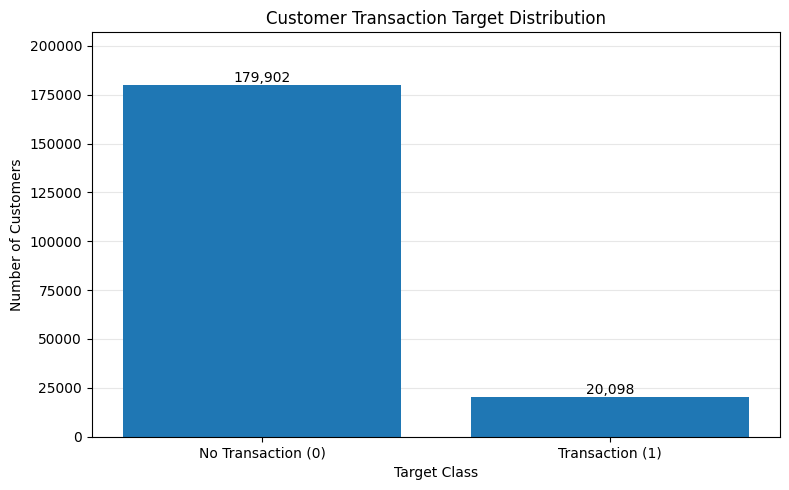

In [4]:

# Cell 4 - Numerical Feature Analysis
# Lightweight EDA - No model training

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Step 1: Calculate descriptive statistics
feature_stats = (
    df[feature_columns]
    .agg(["min", "max", "mean", "std"])
    .T
)

print("NUMERICAL FEATURE SUMMARY")
print("=" * 60)

print("Total numerical features:", len(feature_stats))

print("\nFIRST 10 FEATURES")
print("=" * 60)

display(feature_stats.head(10).round(4))

# Step 2: Check constant features
constant_features = feature_stats[
    feature_stats["std"] == 0
].index.tolist()

print("\nFEATURE VARIABILITY CHECK")
print("=" * 60)

print("Constant features:", len(constant_features))

print(
    "Features with nonzero standard deviation:",
    (feature_stats["std"] > 0).sum()
)

# Step 3: Check for infinite values
infinite_count = np.isinf(
    df[feature_columns].to_numpy()
).sum()

print("\nINFINITE VALUE CHECK")
print("=" * 60)
print("Total infinite values:", infinite_count)

# Step 4: Target imbalance ratio
negative_count = (df["target"] == 0).sum()
positive_count = (df["target"] == 1).sum()

imbalance_ratio = negative_count / positive_count

print("\nTARGET CLASS IMBALANCE")
print("=" * 60)

print(f"Class 0 customers: {negative_count:,}")
print(f"Class 1 customers: {positive_count:,}")
print(f"Imbalance ratio: {imbalance_ratio:.2f}:1")

# Step 5: Visualize target distribution
target_counts = (
    df["target"]
    .value_counts()
    .reindex([0, 1])
)

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    ["No Transaction (0)", "Transaction (1)"],
    target_counts.values
)

ax.set_title("Customer Transaction Target Distribution")
ax.set_xlabel("Target Class")
ax.set_ylabel("Number of Customers")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f"{int(height):,}",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom"
    )

ax.set_ylim(0, target_counts.max() * 1.15)

plt.tight_layout()
plt.show()


In [5]:

# Cell 5 - Stratified Train-Validation Split

from sklearn.model_selection import train_test_split

# Step 1: Define the input features and target
X = df[feature_columns]
y = df["target"]

# Step 2: Create 80% training and 20% validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Step 3: Display dataset shapes
print("TRAIN-VALIDATION SPLIT")
print("=" * 60)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("y_train:", y_train.shape)
print("y_val:", y_val.shape)

# Step 4: Compare target distributions
class_distribution = pd.DataFrame({
    "Original (%)": (
        y.value_counts(normalize=True) * 100
    ),
    "Training (%)": (
        y_train.value_counts(normalize=True) * 100
    ),
    "Validation (%)": (
        y_val.value_counts(normalize=True) * 100
    )
}).reindex([0, 1])

print("\nTARGET DISTRIBUTION")
print("=" * 60)

display(class_distribution.round(2))

# Step 5: Check for overlapping customer records
overlapping_rows = X_train.index.intersection(
    X_val.index
)

print("\nDATA INTEGRITY VERIFICATION")
print("=" * 60)

print("Overlapping rows:", len(overlapping_rows))
print(
    "Total records:",
    len(X_train) + len(X_val)
)
print("Number of model input features:", X_train.shape[1])

# Step 6: Validate the split
assert len(overlapping_rows) == 0
assert len(X_train) + len(X_val) == len(df)
assert X_train.shape[1] == 200
assert y_train.nunique() == 2
assert y_val.nunique() == 2

print("\nTrain-validation split verification: PASSED")


TRAIN-VALIDATION SPLIT
X_train: (160000, 200)
X_val: (40000, 200)
y_train: (160000,)
y_val: (40000,)

TARGET DISTRIBUTION


,Original (%),Training (%),Validation (%)
target,,,
0,89.95,89.95,89.95
1,10.05,10.05,10.05



DATA INTEGRITY VERIFICATION
Overlapping rows: 0
Total records: 200000
Number of model input features: 200

Train-validation split verification: PASSED


TOP 10 FEATURES - TARGET CLASS DIFFERENCES


,Feature,Mean_Target_0,Mean_Target_1,Standardized_Difference,Absolute_Difference
0,var_81,14.781700,14.154800,-0.2722,0.2722
1,var_139,7.963000,5.994800,-0.2560,0.2560
2,var_12,14.028100,13.983900,-0.2325,0.2325
3,var_6,5.391800,5.587000,0.2249,0.2249
4,var_110,5.434800,6.269400,0.2183,0.2183
5,var_146,10.395300,9.863400,-0.2111,0.2111
6,var_26,-4.177800,-2.931400,0.2105,0.2105
7,var_53,5.992100,6.152500,0.2098,0.2098
8,var_76,6.219400,4.552300,-0.2097,0.2097
9,var_174,20.369101,18.892401,-0.2068,0.2068


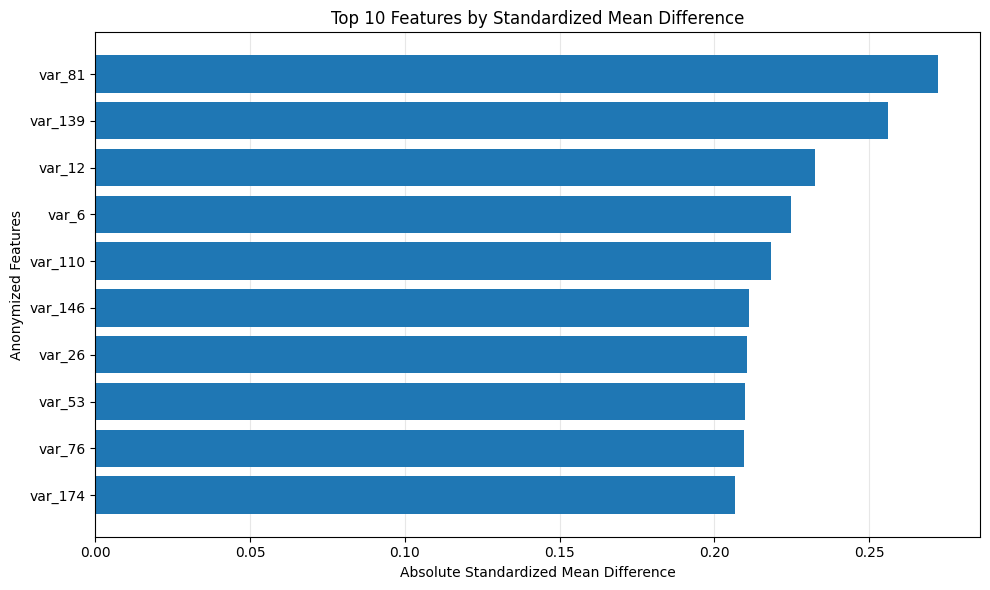


FEATURE SEPARATION SUMMARY
Maximum absolute standardized difference: 0.2722
Median absolute standardized difference: 0.0857
Features with absolute difference > 0.10: 80


In [6]:

# Cell 6 - Target-Based Feature Analysis
# Identify features associated with customer transactions

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Step 1: Calculate feature means for each target class
class_means = X_train.groupby(y_train).mean()

# Step 2: Calculate overall training standard deviations
feature_std = X_train.std()

# Step 3: Calculate standardized mean differences
mean_difference = (
    class_means.loc[1] - class_means.loc[0]
)

standardized_difference = (
    mean_difference / feature_std.replace(0, np.nan)
)

# Step 4: Create a feature comparison table
feature_comparison = pd.DataFrame({
    "Feature": feature_columns,
    "Mean_Target_0": class_means.loc[0].values,
    "Mean_Target_1": class_means.loc[1].values,
    "Standardized_Difference": standardized_difference.values,
    "Absolute_Difference": standardized_difference.abs().values
})

# Step 5: Sort by absolute standardized difference
feature_comparison = feature_comparison.sort_values(
    "Absolute_Difference",
    ascending=False
).reset_index(drop=True)

print("TOP 10 FEATURES - TARGET CLASS DIFFERENCES")
print("=" * 60)

display(feature_comparison.head(10).round(4))

# Step 6: Visualize top 10 features
top_features = feature_comparison.head(10).sort_values(
    "Absolute_Difference"
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    top_features["Feature"],
    top_features["Absolute_Difference"]
)

ax.set_title(
    "Top 10 Features by Standardized Mean Difference"
)

ax.set_xlabel("Absolute Standardized Mean Difference")
ax.set_ylabel("Anonymized Features")
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

# Step 7: Summarize feature separation
print("\nFEATURE SEPARATION SUMMARY")
print("=" * 60)

print(
    "Maximum absolute standardized difference:",
    round(feature_comparison["Absolute_Difference"].max(), 4)
)

print(
    "Median absolute standardized difference:",
    round(feature_comparison["Absolute_Difference"].median(), 4)
)

print(
    "Features with absolute difference > 0.10:",
    (feature_comparison["Absolute_Difference"] > 0.10).sum()
)


In [7]:

# Cell 7 - Baseline Model Development
# Fast baseline models - no hyperparameter search

import time
import pandas as pd

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Step 1: Define lightweight baseline models
baseline_models = {
    "Dummy Majority Class": DummyClassifier(
        strategy="prior"
    ),

    "SGD Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SGDClassifier(
            loss="log_loss",
            class_weight="balanced",
            max_iter=200,
            tol=1e-3,
            random_state=42
        ))
    ])
}

# Step 2: Train and evaluate each model
results = []

for name, model in baseline_models.items():

    print("\n" + "=" * 60)
    print("MODEL:", name)
    print("=" * 60)

    start_time = time.perf_counter()

    model.fit(X_train, y_train)

    training_time = time.perf_counter() - start_time

    # Predictions and probability scores
    y_pred = model.predict(X_val)
    y_prob = model.predict_proba(X_val)[:, 1]

    # Evaluate performance
    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(
            y_val, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_val, y_pred, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(y_val, y_prob),
        "PR_AUC": average_precision_score(y_val, y_prob),
        "Train_Time_Sec": training_time
    }

    results.append(metrics)

    print(f"Training time: {training_time:.2f} seconds")

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_val, y_pred))

    print("\nClassification Report:")
    print(
        classification_report(
            y_val,
            y_pred,
            digits=4,
            zero_division=0
        )
    )

# Step 3: Create comparison table
model_results = pd.DataFrame(results)

print("\n" + "=" * 60)
print("BASELINE MODEL COMPARISON")
print("=" * 60)

display(model_results.round(4))

# Step 4: Save results for later comparisons
baseline_results = model_results.copy()

print("\nBaseline training and evaluation completed.")



MODEL: Dummy Majority Class
Training time: 0.01 seconds

Confusion Matrix:
[[35980     0]
 [ 4020     0]]

Classification Report:
              precision    recall  f1-score   support

           0     0.8995    1.0000    0.9471     35980
           1     0.0000    0.0000    0.0000      4020

    accuracy                         0.8995     40000
   macro avg     0.4497    0.5000    0.4735     40000
weighted avg     0.8091    0.8995    0.8519     40000


MODEL: SGD Logistic Regression
Training time: 19.00 seconds

Confusion Matrix:
[[27762  8218]
 [  988  3032]]

Classification Report:
              precision    recall  f1-score   support

           0     0.9656    0.7716    0.8578     35980
           1     0.2695    0.7542    0.3971      4020

    accuracy                         0.7699     40000
   macro avg     0.6176    0.7629    0.6274     40000
weighted avg     0.8957    0.7699    0.8115     40000


BASELINE MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,Train_Time_Sec
0,Dummy Majority Class,0.8995,0.0000,0.0000,0.0000,0.5000,0.1005,0.0078
1,SGD Logistic Regression,0.7698,0.2695,0.7542,0.3971,0.8453,0.4716,19.0012



Baseline training and evaluation completed.


In [8]:

# Cell 8 - Gaussian Naive Bayes Model
# Fast training - no hyperparameter search

import time
import pandas as pd

from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Step 1: Initialize the model
gnb_model = GaussianNB()

# Step 2: Train the model
start_time = time.perf_counter()

gnb_model.fit(X_train, y_train)

training_time = time.perf_counter() - start_time

# Step 3: Make validation predictions
gnb_pred = gnb_model.predict(X_val)
gnb_prob = gnb_model.predict_proba(X_val)[:, 1]

# Step 4: Evaluate the model
gnb_results = {
    "Model": "Gaussian Naive Bayes",
    "Accuracy": accuracy_score(y_val, gnb_pred),
    "Precision": precision_score(
        y_val, gnb_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_val, gnb_pred, zero_division=0
    ),
    "F1": f1_score(
        y_val, gnb_pred, zero_division=0
    ),
    "ROC_AUC": roc_auc_score(y_val, gnb_prob),
    "PR_AUC": average_precision_score(y_val, gnb_prob),
    "Train_Time_Sec": training_time
}

print("GAUSSIAN NAIVE BAYES RESULTS")
print("=" * 60)

print(f"Training time: {training_time:.2f} seconds")

print("\nCONFUSION MATRIX")
print("=" * 60)
print(confusion_matrix(y_val, gnb_pred))

print("\nCLASSIFICATION REPORT")
print("=" * 60)
print(
    classification_report(
        y_val,
        gnb_pred,
        digits=4,
        zero_division=0
    )
)

# Step 5: Add Gaussian NB to previous comparison
model_results = pd.concat(
    [
        baseline_results,
        pd.DataFrame([gnb_results])
    ],
    ignore_index=True
)

print("\nMODEL COMPARISON - 3 MODELS")
print("=" * 60)

display(
    model_results.sort_values(
        "PR_AUC",
        ascending=False
    ).round(4)
)

print("\nCell 8 completed successfully.")


GAUSSIAN NAIVE BAYES RESULTS
Training time: 0.47 seconds

CONFUSION MATRIX
[[35250   730]
 [ 2543  1477]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0     0.9327    0.9797    0.9556     35980
           1     0.6692    0.3674    0.4744      4020

    accuracy                         0.9182     40000
   macro avg     0.8010    0.6736    0.7150     40000
weighted avg     0.9062    0.9182    0.9073     40000


MODEL COMPARISON - 3 MODELS


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,Train_Time_Sec
2,Gaussian Naive Bayes,0.9182,0.6692,0.3674,0.4744,0.8822,0.5613,0.4690
1,SGD Logistic Regression,0.7698,0.2695,0.7542,0.3971,0.8453,0.4716,19.0012
0,Dummy Majority Class,0.8995,0.0000,0.0000,0.0000,0.5000,0.1005,0.0078



Cell 8 completed successfully.


In [9]:

# Cell 9 - Gaussian NB Threshold Optimization
# Uses an internal training split to avoid threshold-selection leakage

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix
)

# Step 1: Create an internal split from training data only
X_fit, X_tune, y_fit, y_tune = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=123
)

# Step 2: Train a separate Gaussian NB for threshold selection
gnb_tuning_model = clone(gnb_model)
gnb_tuning_model.fit(X_fit, y_fit)

tune_prob = gnb_tuning_model.predict_proba(X_tune)[:, 1]

# Step 3: Find threshold maximizing positive-class F1
precision, recall, thresholds = precision_recall_curve(
    y_tune, tune_prob
)

f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / np.maximum(precision[:-1] + recall[:-1], 1e-12)
)

best_index = np.argmax(f1_scores)
best_threshold = float(thresholds[best_index])

print("THRESHOLD SELECTION - TRAINING DATA ONLY")
print("=" * 60)
print(f"Selected threshold: {best_threshold:.6f}")
print(f"Internal tuning F1: {f1_scores[best_index]:.4f}")

# Step 4: Evaluate the already-trained full Gaussian NB model
# on the held-out validation set at both thresholds
threshold_results = []

for label, threshold in [
    ("Default threshold", 0.50),
    ("Tuned threshold", best_threshold)
]:
    predictions = (gnb_prob >= threshold).astype(int)

    threshold_results.append({
        "Setting": label,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions),
        "Recall": recall_score(y_val, predictions),
        "F1": f1_score(y_val, predictions),
        "Predicted_Positive": int(predictions.sum())
    })

    print(f"\n{label.upper()}")
    print(f"Threshold: {threshold:.6f}")
    print("Confusion Matrix:")
    print(confusion_matrix(y_val, predictions))

print("\nGAUSSIAN NB THRESHOLD COMPARISON")
print("=" * 60)

threshold_comparison = pd.DataFrame(threshold_results)
display(threshold_comparison.round(4))


THRESHOLD SELECTION - TRAINING DATA ONLY
Selected threshold: 0.271175
Internal tuning F1: 0.5538

DEFAULT THRESHOLD
Threshold: 0.500000
Confusion Matrix:
[[35250   730]
 [ 2543  1477]]

TUNED THRESHOLD
Threshold: 0.271175
Confusion Matrix:
[[33593  2387]
 [ 1674  2346]]

GAUSSIAN NB THRESHOLD COMPARISON


,Setting,Threshold,Accuracy,Precision,Recall,F1,Predicted_Positive
0,Default threshold,0.5000,0.9182,0.6692,0.3674,0.4744,2207
1,Tuned threshold,0.2712,0.8985,0.4957,0.5836,0.5360,4733


In [10]:

# Cell 10 - Histogram Gradient Boosting
# Controlled training sample and limited boosting iterations

import time
import pandas as pd

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Step 1: Select a stratified training sample
X_gb_train, _, y_gb_train, _ = train_test_split(
    X_train,
    y_train,
    train_size=60000,
    stratify=y_train,
    random_state=42
)

print("HISTOGRAM GRADIENT BOOSTING")
print("=" * 60)

print("Training samples:", len(X_gb_train))
print("Validation samples:", len(X_val))
print("Number of features:", X_gb_train.shape[1])

# Step 2: Initialize a computationally limited model
hgb_model = HistGradientBoostingClassifier(
    max_iter=60,
    learning_rate=0.08,
    max_leaf_nodes=15,
    max_bins=63,
    min_samples_leaf=40,
    l2_regularization=1.0,
    early_stopping=True,
    validation_fraction=0.10,
    n_iter_no_change=5,
    random_state=42
)

# Step 3: Train the model
start_time = time.perf_counter()

hgb_model.fit(X_gb_train, y_gb_train)

training_time = time.perf_counter() - start_time

# Step 4: Predict on the original validation set
hgb_pred = hgb_model.predict(X_val)
hgb_prob = hgb_model.predict_proba(X_val)[:, 1]

# Step 5: Calculate metrics
hgb_results = {
    "Model": "HistGradientBoosting (60k)",
    "Accuracy": accuracy_score(y_val, hgb_pred),
    "Precision": precision_score(
        y_val, hgb_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_val, hgb_pred, zero_division=0
    ),
    "F1": f1_score(
        y_val, hgb_pred, zero_division=0
    ),
    "ROC_AUC": roc_auc_score(y_val, hgb_prob),
    "PR_AUC": average_precision_score(y_val, hgb_prob),
    "Train_Time_Sec": training_time
}

print("\nTRAINING SUMMARY")
print("=" * 60)

print(f"Training time: {training_time:.2f} seconds")
print("Boosting iterations used:", hgb_model.n_iter_)

print("\nCONFUSION MATRIX")
print("=" * 60)

print(confusion_matrix(y_val, hgb_pred))

print("\nCLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_val,
        hgb_pred,
        digits=4,
        zero_division=0
    )
)

# Step 6: Update model comparison
model_results = model_results[
    model_results["Model"] != "HistGradientBoosting (60k)"
]

model_results = pd.concat(
    [
        model_results,
        pd.DataFrame([hgb_results])
    ],
    ignore_index=True
)

print("\nMODEL COMPARISON - 4 ALGORITHMS")
print("=" * 60)

display(
    model_results.sort_values(
        "PR_AUC",
        ascending=False
    ).round(4)
)

print("\nCell 10 completed successfully.")


HISTOGRAM GRADIENT BOOSTING
Training samples: 60000
Validation samples: 40000
Number of features: 200

TRAINING SUMMARY
Training time: 8.26 seconds
Boosting iterations used: 60

CONFUSION MATRIX
[[35977     3]
 [ 4000    20]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0     0.8999    0.9999    0.9473     35980
           1     0.8696    0.0050    0.0099      4020

    accuracy                         0.8999     40000
   macro avg     0.8848    0.5024    0.4786     40000
weighted avg     0.8969    0.8999    0.8531     40000


MODEL COMPARISON - 4 ALGORITHMS


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,Train_Time_Sec
2,Gaussian Naive Bayes,0.9182,0.6692,0.3674,0.4744,0.8822,0.5613,0.4690
1,SGD Logistic Regression,0.7698,0.2695,0.7542,0.3971,0.8453,0.4716,19.0012
3,HistGradientBoosting (60k),0.8999,0.8696,0.0050,0.0099,0.8263,0.4154,8.2628
0,Dummy Majority Class,0.8995,0.0000,0.0000,0.0000,0.5000,0.1005,0.0078



Cell 10 completed successfully.


In [11]:

# Cell 11 - Gaussian Naive Bayes Hyperparameter Tuning
# Lightweight tuning using training data only

import time
import numpy as np
import pandas as pd

from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_recall_curve,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Step 1: Internal training and tuning split
X_fit, X_tune, y_fit, y_tune = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=123
)

# Step 2: Define a small parameter search
smoothing_values = [
    1e-12, 1e-9, 1e-6,
    1e-4, 1e-2, 1e-1
]

tuning_results = []

start_time = time.perf_counter()

# Step 3: Evaluate on internal tuning data
for smoothing in smoothing_values:

    model = GaussianNB(var_smoothing=smoothing)
    model.fit(X_fit, y_fit)

    probabilities = model.predict_proba(X_tune)[:, 1]

    tuning_results.append({
        "var_smoothing": smoothing,
        "ROC_AUC": roc_auc_score(y_tune, probabilities),
        "PR_AUC": average_precision_score(
            y_tune, probabilities
        )
    })

# Step 4: Compare smoothing values
tuning_df = pd.DataFrame(tuning_results)

print("GAUSSIAN NB HYPERPARAMETER RESULTS")
print("=" * 60)

display(
    tuning_df.sort_values(
        "PR_AUC", ascending=False
    ).round(6)
)

# Step 5: Select the best smoothing using PR-AUC
best_smoothing = float(
    tuning_df.loc[
        tuning_df["PR_AUC"].idxmax(),
        "var_smoothing"
    ]
)

print("\nBEST HYPERPARAMETER")
print("=" * 60)
print("Best var_smoothing:", best_smoothing)

# Step 6: Select a threshold using internal training data
tuning_model = GaussianNB(
    var_smoothing=best_smoothing
)

tuning_model.fit(X_fit, y_fit)

tune_prob = tuning_model.predict_proba(X_tune)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_tune, tune_prob
)

f1_values = (
    2 * precision[:-1] * recall[:-1]
    / np.maximum(
        precision[:-1] + recall[:-1],
        1e-12
    )
)

best_index = np.argmax(f1_values)
tuned_nb_threshold = float(thresholds[best_index])

print("Selected threshold:", round(tuned_nb_threshold, 6))
print("Internal tuning F1:", round(f1_values[best_index], 4))

# Step 7: Train optimized model on full training data
tuned_nb_model = GaussianNB(
    var_smoothing=best_smoothing
)

tuned_nb_model.fit(X_train, y_train)

# Step 8: Evaluate on validation data
tuned_nb_prob = tuned_nb_model.predict_proba(X_val)[:, 1]

tuned_nb_pred = (
    tuned_nb_prob >= tuned_nb_threshold
).astype(int)

tuned_nb_metrics = {
    "Accuracy": accuracy_score(y_val, tuned_nb_pred),
    "Precision": precision_score(y_val, tuned_nb_pred),
    "Recall": recall_score(y_val, tuned_nb_pred),
    "F1": f1_score(y_val, tuned_nb_pred),
    "ROC_AUC": roc_auc_score(y_val, tuned_nb_prob),
    "PR_AUC": average_precision_score(y_val, tuned_nb_prob)
}

print("\nOPTIMIZED GAUSSIAN NB - VALIDATION RESULTS")
print("=" * 60)

display(
    pd.DataFrame([tuned_nb_metrics]).round(4)
)

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_val, tuned_nb_pred))

print("\nTOTAL EXECUTION TIME")
print(
    f"{time.perf_counter() - start_time:.2f} seconds"
)


GAUSSIAN NB HYPERPARAMETER RESULTS


,var_smoothing,ROC_AUC,PR_AUC
2,0.000001,0.887531,0.583308
1,0.000000,0.887352,0.583145
0,0.000000,0.887350,0.583141
3,0.000100,0.884172,0.572562
4,0.010000,0.854084,0.495581
5,0.100000,0.811337,0.398336



BEST HYPERPARAMETER
Best var_smoothing: 1e-06
Selected threshold: 0.264069
Internal tuning F1: 0.5542

OPTIMIZED GAUSSIAN NB - VALIDATION RESULTS


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,0.9046,0.5236,0.5682,0.545,0.8882,0.5763



CONFUSION MATRIX
[[33902  2078]
 [ 1736  2284]]

TOTAL EXECUTION TIME
4.31 seconds


FINAL MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Gaussian NB (Optimized),0.9046,0.5236,0.5682,0.5450,0.8882,0.5763
1,Gaussian Naive Bayes,0.9182,0.6692,0.3674,0.4744,0.8822,0.5613
2,SGD Logistic Regression,0.7698,0.2695,0.7542,0.3971,0.8453,0.4716
3,HistGradientBoosting (60k),0.8999,0.8696,0.0050,0.0099,0.8263,0.4154
4,Dummy Majority Class,0.8995,0.0000,0.0000,0.0000,0.5000,0.1005



BEST MODEL BY PR-AUC
Gaussian NB (Optimized)


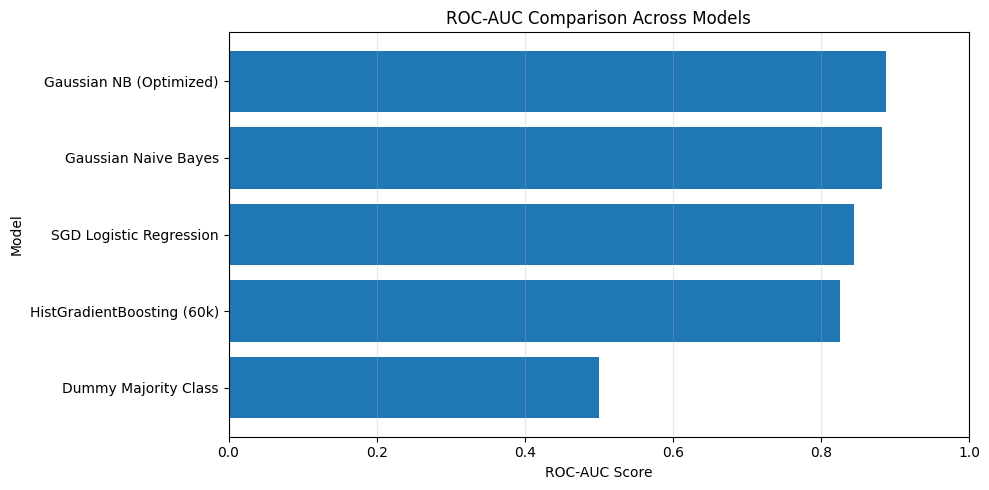

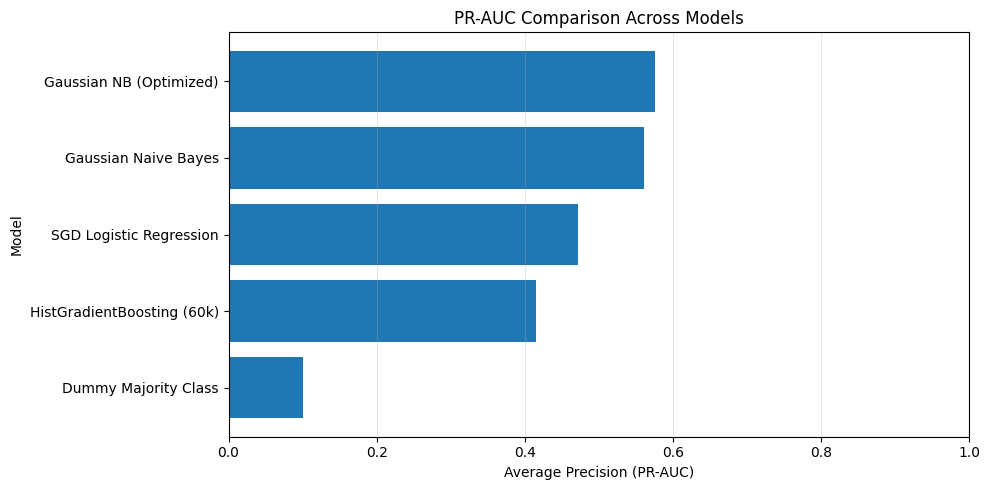


Final model comparison completed successfully.


In [12]:

# Cell 12 - Final Model Comparison and Visualization

import pandas as pd
import matplotlib.pyplot as plt

# Step 1: Add the optimized Gaussian NB results
optimized_row = {
    "Model": "Gaussian NB (Optimized)",
    "Accuracy": tuned_nb_metrics["Accuracy"],
    "Precision": tuned_nb_metrics["Precision"],
    "Recall": tuned_nb_metrics["Recall"],
    "F1": tuned_nb_metrics["F1"],
    "ROC_AUC": tuned_nb_metrics["ROC_AUC"],
    "PR_AUC": tuned_nb_metrics["PR_AUC"],
    "Train_Time_Sec": float("nan")
}

# Step 2: Combine existing and optimized results
final_model_comparison = pd.concat(
    [
        model_results,
        pd.DataFrame([optimized_row])
    ],
    ignore_index=True
)

# Step 3: Rank models by PR-AUC
final_model_comparison = (
    final_model_comparison
    .sort_values("PR_AUC", ascending=False)
    .reset_index(drop=True)
)

print("FINAL MODEL COMPARISON")
print("=" * 65)

display(
    final_model_comparison[
        [
            "Model", "Accuracy", "Precision",
            "Recall", "F1", "ROC_AUC", "PR_AUC"
        ]
    ].round(4)
)

# Step 4: Identify best model by ranking performance
best_model_name = final_model_comparison.iloc[0]["Model"]

print("\nBEST MODEL BY PR-AUC")
print("=" * 65)
print(best_model_name)

# Step 5: Plot ROC-AUC comparison
plot_df = final_model_comparison.sort_values("ROC_AUC")

plt.figure(figsize=(10, 5))
plt.barh(plot_df["Model"], plot_df["ROC_AUC"])
plt.xlabel("ROC-AUC Score")
plt.ylabel("Model")
plt.title("ROC-AUC Comparison Across Models")
plt.xlim(0, 1)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# Step 6: Plot PR-AUC comparison
plot_df = final_model_comparison.sort_values("PR_AUC")

plt.figure(figsize=(10, 5))
plt.barh(plot_df["Model"], plot_df["PR_AUC"])
plt.xlabel("Average Precision (PR-AUC)")
plt.ylabel("Model")
plt.title("PR-AUC Comparison Across Models")
plt.xlim(0, 1)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

print("\nFinal model comparison completed successfully.")


In [13]:

# Cell 13 - Save Final Model and Metadata
# No model training required

from pathlib import Path
import joblib
import json
import numpy as np
import pandas as pd

# Step 1: Create project output folder
output_dir = Path("customer_transaction_outputs")
output_dir.mkdir(exist_ok=True)

# Step 2: Save trained Gaussian NB model
model_path = output_dir / "optimized_gaussian_nb.joblib"

joblib.dump(tuned_nb_model, model_path)

# Step 3: Prepare model metadata
metadata = {
    "project": "PRCP-1003 Customer Transaction Prediction",
    "model": "Gaussian Naive Bayes",
    "model_parameter": {
        "var_smoothing": float(best_smoothing)
    },
    "classification_threshold": float(tuned_nb_threshold),
    "feature_names": list(feature_columns),
    "number_of_features": len(feature_columns),
    "training_samples": len(X_train),
    "validation_samples": len(X_val),
    "target_labels": {
        "0": "No Transaction",
        "1": "Transaction"
    },
    "validation_metrics": {
        key: float(value)
        for key, value in tuned_nb_metrics.items()
    },
    "selection_metric": "Average Precision (PR-AUC)",
    "note": (
        "Hyperparameter and threshold were selected "
        "using an internal training split. "
        "Validation performance is not an independent "
        "production test."
    )
}

# Step 4: Save metadata as JSON
metadata_path = output_dir / "model_metadata.json"

with open(metadata_path, "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=4)

# Step 5: Save final model comparison table
comparison_path = output_dir / "final_model_comparison.csv"

final_model_comparison.to_csv(
    comparison_path,
    index=False
)

print("MODEL FILES SAVED")
print("=" * 60)

for file in output_dir.iterdir():
    size_kb = file.stat().st_size / 1024
    print(f"{file.name}: {size_kb:.2f} KB")

# Step 6: Reload the saved model and metadata
loaded_model = joblib.load(model_path)

with open(metadata_path, "r", encoding="utf-8") as file:
    loaded_metadata = json.load(file)

loaded_threshold = loaded_metadata["classification_threshold"]

# Step 7: Test predictions on existing validation records
# Select examples from both actual classes
sample_indices = (
    y_val[y_val == 0].index[:3].tolist()
    + y_val[y_val == 1].index[:3].tolist()
)

sample_X = X_val.loc[sample_indices]
sample_y = y_val.loc[sample_indices]

loaded_prob = loaded_model.predict_proba(sample_X)[:, 1]

loaded_pred = (
    loaded_prob >= loaded_threshold
).astype(int)

# Step 8: Verify saved and original model agree
original_prob = tuned_nb_model.predict_proba(
    sample_X
)[:, 1]

assert np.allclose(loaded_prob, original_prob)
assert loaded_metadata["feature_names"] == feature_columns

print("\nSAVED MODEL VERIFICATION")
print("=" * 60)

print("Model loaded successfully: YES")
print("Feature count:", len(loaded_metadata["feature_names"]))
print("Classification threshold:", round(loaded_threshold, 6))
print("Predictions match original model: YES")

# Step 9: Show sample customer predictions
sample_results = pd.DataFrame({
    "Actual_Target": sample_y.to_numpy(),
    "Transaction_Probability": loaded_prob,
    "Predicted_Target": loaded_pred
})

print("\nSAMPLE CUSTOMER PREDICTIONS")
print("=" * 60)

display(sample_results.round(4))

print("\nCell 13 completed successfully.")


MODEL FILES SAVED
final_model_comparison.csv: 0.70 KB
model_metadata.json: 4.69 KB
optimized_gaussian_nb.joblib: 5.95 KB

SAVED MODEL VERIFICATION
Model loaded successfully: YES
Feature count: 200
Classification threshold: 0.264069
Predictions match original model: YES

SAMPLE CUSTOMER PREDICTIONS


,Actual_Target,Transaction_Probability,Predicted_Target
0,0,0.0027,0
1,0,0.1102,0
2,0,0.0032,0
3,1,0.6947,1
4,1,0.2972,1
5,1,0.7293,1



Cell 13 completed successfully.


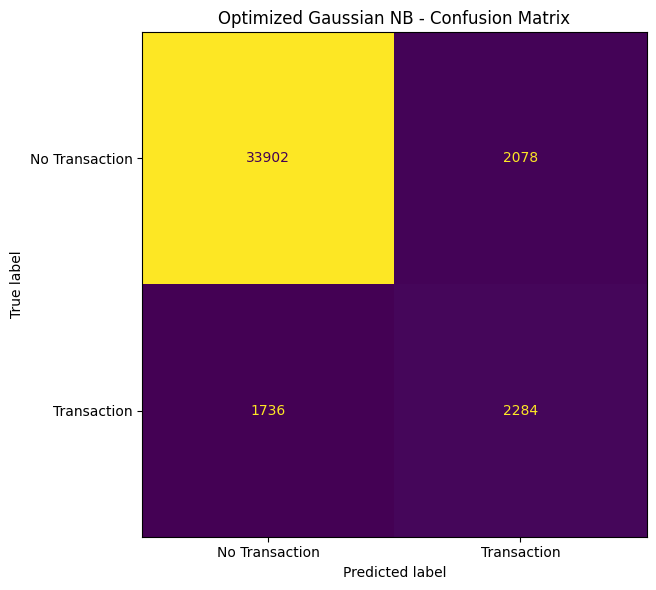

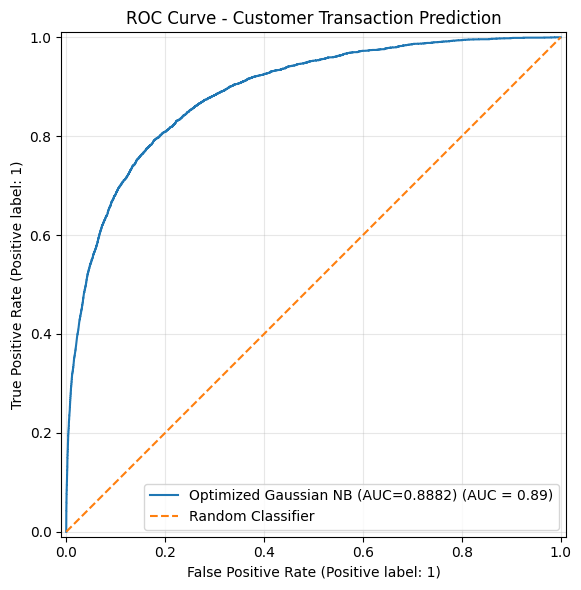

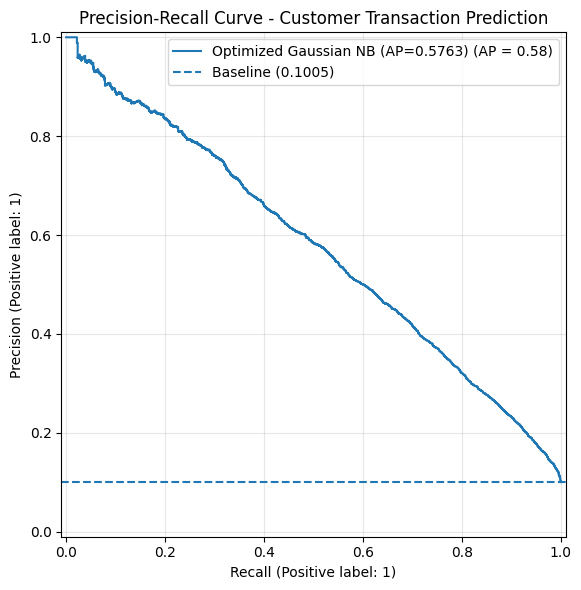

FINAL MODEL EVALUATION
ROC-AUC: 0.8882
Average Precision (PR-AUC): 0.5763

SAVED EVALUATION FIGURES
PASS - confusion_matrix.png (32.34 KB)
PASS - roc_curve.png (62.39 KB)
PASS - precision_recall_curve.png (56.34 KB)

Cell 14 completed successfully.


In [14]:

# Cell 14 - Final Model Evaluation Visualizations
# No retraining - uses saved model predictions

import matplotlib.pyplot as plt

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

from pathlib import Path

# Output folder
output_dir = Path("customer_transaction_outputs")
output_dir.mkdir(exist_ok=True)

# ------------------------------------------------
# 1. Confusion Matrix
# ------------------------------------------------

cm = confusion_matrix(y_val, tuned_nb_pred)

fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Transaction", "Transaction"]
).plot(
    ax=ax,
    values_format="d",
    colorbar=False
)

ax.set_title("Optimized Gaussian NB - Confusion Matrix")

plt.tight_layout()

fig.savefig(
    output_dir / "confusion_matrix.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------
# 2. ROC Curve
# ------------------------------------------------

roc_auc = roc_auc_score(y_val, tuned_nb_prob)

fig, ax = plt.subplots(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_val,
    tuned_nb_prob,
    name=f"Optimized Gaussian NB (AUC={roc_auc:.4f})",
    ax=ax
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

ax.set_title("ROC Curve - Customer Transaction Prediction")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()

fig.savefig(
    output_dir / "roc_curve.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------
# 3. Precision-Recall Curve
# ------------------------------------------------

average_precision = average_precision_score(
    y_val,
    tuned_nb_prob
)

fig, ax = plt.subplots(figsize=(8, 6))

PrecisionRecallDisplay.from_predictions(
    y_val,
    tuned_nb_prob,
    name=f"Optimized Gaussian NB (AP={average_precision:.4f})",
    ax=ax
)

# Baseline: positive-class proportion
positive_rate = y_val.mean()

ax.axhline(
    y=positive_rate,
    linestyle="--",
    label=f"Baseline ({positive_rate:.4f})"
)

ax.set_title(
    "Precision-Recall Curve - Customer Transaction Prediction"
)

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()

fig.savefig(
    output_dir / "precision_recall_curve.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------
# 4. Verify Saved Figures
# ------------------------------------------------

print("FINAL MODEL EVALUATION")
print("=" * 60)

print(f"ROC-AUC: {roc_auc:.4f}")
print(f"Average Precision (PR-AUC): {average_precision:.4f}")

print("\nSAVED EVALUATION FIGURES")
print("=" * 60)

figure_names = [
    "confusion_matrix.png",
    "roc_curve.png",
    "precision_recall_curve.png"
]

for filename in figure_names:
    file_path = output_dir / filename

    if file_path.exists():
        size_kb = file_path.stat().st_size / 1024
        print(f"PASS - {filename} ({size_kb:.2f} KB)")
    else:
        print(f"FAIL - {filename}")

print("\nCell 14 completed successfully.")



# Customer Transaction Prediction (PRCP-1003)
## Final Analysis Report, Challenges and Conclusion

### 1. Project Objective

The objective of this project is to develop a machine learning
classification model that predicts whether a banking customer will
make a specific transaction in the future.

The target variable has two classes:
- 0: Customer will not make the transaction.
- 1: Customer will make the transaction.

### 2. Dataset Description

The dataset contains 200,000 customer records and 202 columns.

- Customer identifier: ID_code
- Numerical features: 200 (var_0 to var_199)
- Target column: target
- Training records: 160,000
- Validation records: 40,000

All predictive features are anonymized, so their real-world
banking meanings are unknown.

### 3. Exploratory Data Analysis Findings

The following observations were obtained:

- No missing values were detected.
- No duplicate customer IDs or duplicate records were found.
- All 200 numerical features had nonzero variance.
- No infinite numerical values were detected.
- Class 0 contained 179,902 customers (89.95%).
- Class 1 contained 20,098 customers (10.05%).
- The class imbalance ratio was approximately 8.95:1.

The target-based feature analysis identified var_81, var_139,
var_12, var_6 and var_110 among the features with the largest
standardized mean differences.

However, individual feature differences were relatively small.
Therefore, all 200 numerical features were retained for modeling.

### 4. Data Preparation

An 80:20 stratified train-validation split was performed to
preserve the original target-class proportions.

The ID_code column was excluded from the model inputs.

Feature scaling was applied within the SGD Logistic Regression
pipeline to avoid validation data leakage.

Missing-value imputation and duplicate removal were unnecessary
because the dataset passed the initial data quality checks.

### 5. Machine Learning Models Evaluated

Four classification algorithms were evaluated:

1. Dummy Majority Classifier
2. SGD Logistic Regression
3. Gaussian Naive Bayes
4. Histogram Gradient Boosting

Gaussian Naive Bayes was additionally optimized through
hyperparameter tuning and decision threshold selection.

The main comparison metrics were ROC-AUC and Average Precision
(PR-AUC), supported by accuracy, precision, recall and F1-score.

### 6. Final Model Selection

The best-performing evaluated model was Optimized Gaussian
Naive Bayes.

Selected configuration:
- var_smoothing: 0.000001
- Classification threshold: 0.264069
- Number of input features: 200

Validation performance:
- Accuracy: 90.46%
- Precision: 52.36%
- Recall: 56.82%
- F1-score: 0.5450
- ROC-AUC: 0.8882
- Average Precision (PR-AUC): 0.5763

Validation confusion matrix:
- True Negatives: 33,902
- False Positives: 2,078
- False Negatives: 1,736
- True Positives: 2,284

The optimized model identified 2,284 of the 4,020 actual
transacting customers in the validation dataset.

### 7. Challenges Faced and Solutions

**Challenge 1: Highly imbalanced target classes**

Approximately 90% of customers belonged to class 0.

Solution:
A stratified split was used. Models were evaluated using
precision, recall, F1-score, ROC-AUC and Average Precision
instead of relying only on accuracy.

**Challenge 2: Anonymized features**

The dataset contained 200 numerical features with unknown
business meanings.

Solution:
Statistical analysis and standardized mean differences were
used to explore feature behavior without assigning unsupported
banking interpretations.

**Challenge 3: Low minority-class recall**

Gaussian Naive Bayes initially detected only 36.74% of
transacting customers.

Solution:
A classification threshold was selected using an internal
training split. This improved the recall and F1-score compared
with the initial default-threshold model.

**Challenge 4: Balancing precision and recall**

A lower threshold identified more transacting customers but
also increased false-positive predictions.

Solution:
The decision threshold was selected to maximize positive-class
F1-score on internal tuning data. Business-specific costs should
guide threshold selection before actual deployment.

**Challenge 5: Computational efficiency**

The dataset contained 200,000 rows and 200 predictive features.

Solution:
Memory-efficient float32 storage was used. Lightweight models
were evaluated first, and Histogram Gradient Boosting was
tested using a limited training sample and a restricted number
of iterations.

### 8. Limitations

The final model still missed 1,736 of the 4,020 actual
transacting customers in validation.

Because the features are anonymized, explanations of individual
predictions in business terms are limited.

The validation dataset was used to compare model candidates.
A separate, untouched test dataset and further checks for
probability calibration, data drift and operational costs are
necessary before any production deployment.

### 9. Conclusion

This project demonstrated how machine learning can identify
customers who are more likely to make a future banking
transaction.

Among the evaluated approaches, Optimized Gaussian Naive Bayes
achieved the highest validation PR-AUC of 0.5763 and ROC-AUC
of 0.8882.

Its performance was substantially better than the majority-class
baseline. Hyperparameter and threshold optimization improved
its ability to detect transacting customers.

The model is recommended as the leading candidate from this
project's experiments, subject to independent testing and
production readiness assessment.

### 10. Future Scope

Future improvements may include:
- Evaluating additional algorithms on an independent test set.
- Assessing probability calibration.
- Selecting thresholds based on business-specific costs.
- Investigating model drift and changing customer behavior.
- Improving model interpretability and deployment monitoring.



# Cell 16 - GitHub Project Documentation
# No model training

from pathlib import Path
from importlib.metadata import version

project_dir = Path.cwd()
output_dir = project_dir / "customer_transaction_outputs"

# --------------------------------------------------
# 1. Create README.md
# --------------------------------------------------

readme = """# Customer Transaction Prediction (PRCP-1003)

## Project Overview

This machine learning project predicts whether a bank
customer will make a specific future transaction.

The dataset contains 200,000 customers, 200 anonymized
numerical features, one customer identifier (ID_code),
and a binary target.

- Target 0: No transaction
- Target 1: Transaction

## Dataset

- Total records: 200,000
- Numerical features: 200
- Missing values: 0
- Duplicate customer IDs: 0
- Class 0: 179,902 (89.95%)
- Class 1: 20,098 (10.05%)

The dataset is anonymized, so the real-world meanings
of individual features are unavailable.

## Methodology

1. Dataset inspection and statistical analysis
2. Missing-value and duplicate checks
3. Target distribution and feature analysis
4. Stratified 80:20 train-validation split
5. Baseline model comparison
6. Hyperparameter and threshold optimization
7. Model evaluation and export

## Models Evaluated

| Model | ROC-AUC | Average Precision |
|---|---:|---:|
| Dummy Majority Class | 0.5000 | 0.1005 |
| SGD Logistic Regression | 0.8453 | 0.4716 |
| Gaussian Naive Bayes | 0.8822 | 0.5613 |
| Histogram Gradient Boosting (60k) | 0.8263 | 0.4154 |
| Optimized Gaussian NB | 0.8882 | 0.5763 |

Histogram Gradient Boosting was trained on a
stratified 60,000-record training subset.

## Selected Model

**Optimized Gaussian Naive Bayes**

- var_smoothing: 1e-6
- Decision threshold: 0.264069
- Accuracy: 90.46%
- Precision: 52.36%
- Recall: 56.82%
- F1-score: 0.5450
- ROC-AUC: 0.8882
- Average Precision: 0.5763

### Validation Confusion Matrix

| Actual / Predicted | No Transaction | Transaction |
|---|---:|---:|
| No Transaction | 33,902 | 2,078 |
| Transaction | 1,736 | 2,284 |

## Evaluation Visualizations

### Confusion Matrix
![Confusion Matrix](customer_transaction_outputs/confusion_matrix.png)

### ROC Curve
![ROC Curve](customer_transaction_outputs/roc_curve.png)

### Precision-Recall Curve
![Precision-Recall Curve](customer_transaction_outputs/precision_recall_curve.png)

## Project Outputs

The `customer_transaction_outputs` folder contains:

- `optimized_gaussian_nb.joblib`
- `model_metadata.json`
- `final_model_comparison.csv`
- `confusion_matrix.png`
- `roc_curve.png`
- `precision_recall_curve.png`

## How to Run

1. Install Python and Jupyter Notebook.
2. Install packages:
   `pip install -r requirements.txt`
3. Download the original dataset from the project source.
4. Place `Train.csv` in the notebook folder.
5. Open the project notebook in Jupyter.
6. Run the notebook cells in order.

To use the exported model, load the trusted joblib
file and read `model_metadata.json`.

Provide the 200 numerical features in the saved order.
Apply the stored decision threshold to the positive-class
scores returned by `predict_proba()`.

## Challenges

- Strong target class imbalance
- Anonymized numerical features
- Low minority-class recall at the default threshold
- Precision-recall trade-off
- Computational constraints on a large dataset

These challenges were addressed using stratified
splitting, appropriate evaluation metrics, threshold
selection, and efficient model training.

## Limitations

The model still misses some transacting customers.
The model probabilities have not been independently
calibrated.

The validation dataset was used for model comparison,
so reported metrics are development-validation results.

The project has not been assessed on an independent
external test dataset or validated for banking production.

Further testing, calibration, business-cost analysis,
and monitoring would be needed before deployment.

## Conclusion

Optimized Gaussian Naive Bayes achieved the highest
validation Average Precision among the evaluated models.

It is the leading candidate from this capstone study,
rather than a production-ready banking system.
"""

readme_path = project_dir / "README.md"
readme_path.write_text(readme, encoding="utf-8")

# --------------------------------------------------
# 2. Create requirements.txt
# --------------------------------------------------

packages = [
    "numpy",
    "pandas",
    "scikit-learn",
    "matplotlib",
    "joblib"
]

requirements = "\n".join(
    f"{package}=={version(package)}"
    for package in packages
) + "\n"

requirements_path = project_dir / "requirements.txt"

requirements_path.write_text(
    requirements,
    encoding="utf-8"
)

# --------------------------------------------------
# 3. Create .gitignore
# --------------------------------------------------

gitignore = """
# Raw datasets
Train.csv
train.csv
Test.csv
test.csv

# Jupyter temporary files
.ipynb_checkpoints/

# Python temporary files
__pycache__/
*.pyc

# Virtual environments
.venv/
venv/

# Local data folders
data/
dataset/

# Logs
*.log
"""

gitignore_path = project_dir / ".gitignore"

gitignore_path.write_text(
    gitignore.strip() + "\n",
    encoding="utf-8"
)

# --------------------------------------------------
# 4. Verify the project files
# --------------------------------------------------

print("PROJECT DOCUMENTATION CREATED")
print("=" * 60)

required_files = [
    readme_path,
    requirements_path,
    gitignore_path,
    output_dir / "optimized_gaussian_nb.joblib",
    output_dir / "model_metadata.json",
    output_dir / "final_model_comparison.csv",
    output_dir / "confusion_matrix.png",
    output_dir / "roc_curve.png",
    output_dir / "precision_recall_curve.png"
]

all_present = True

for file in required_files:
    if file.is_file():
        print("PASS -", file.relative_to(project_dir))
    else:
        print("FAIL -", file.relative_to(project_dir))
        all_present = False

# Check notebooks
print("\nJUPYTER NOTEBOOK FILES")
print("=" * 60)

notebooks = sorted(project_dir.glob("*.ipynb"))

if notebooks:
    for notebook in notebooks:
        print(
            notebook.name,
            "-",
            f"{notebook.stat().st_size / (1024**2):.2f} MB"
        )
else:
    print("No notebook found in project directory.")

# Final status
print("\nFINAL VERIFICATION")
print("=" * 60)

print("Required files present:", all_present)
print("Notebook found:", bool(notebooks))

if all_present and notebooks:
    print("GitHub file preparation: PASSED")
else:
    print("GitHub file preparation: NEEDS REVIEW")


In [17]:

# Cell 17 - Fix Missing GitHub Files
# No model training

from pathlib import Path
from importlib.metadata import version

project_dir = Path.cwd()

print("CURRENT PROJECT FOLDER")
print("=" * 60)
print(project_dir)

# 1. README.md
readme = """# Customer Transaction Prediction (PRCP-1003)

## Project Overview
This project predicts whether a banking customer will make
a future transaction using machine learning.

## Dataset
- Records: 200,000
- Numerical features: 200
- Target: 0 (No Transaction), 1 (Transaction)
- Missing values: 0
- Duplicate records: 0
- Target imbalance: 89.95% vs 10.05%

## Methodology
1. Dataset inspection and EDA
2. Data quality assessment
3. Stratified 80:20 train-validation split
4. Model development and comparison
5. Hyperparameter and threshold optimization
6. Model evaluation and export

## Model Comparison

| Model | ROC-AUC | PR-AUC |
|---|---:|---:|
| Dummy Classifier | 0.5000 | 0.1005 |
| SGD Logistic Regression | 0.8453 | 0.4716 |
| Gaussian Naive Bayes | 0.8822 | 0.5613 |
| Histogram Gradient Boosting (60k) | 0.8263 | 0.4154 |
| Optimized Gaussian NB | 0.8882 | 0.5763 |

## Selected Model
Optimized Gaussian Naive Bayes

- var_smoothing: 1e-6
- Decision threshold: 0.264069
- Accuracy: 90.46%
- Precision: 52.36%
- Recall: 56.82%
- F1-score: 0.5450
- ROC-AUC: 0.8882
- PR-AUC (Average Precision): 0.5763

## Evaluation Results

### Confusion Matrix
![Confusion Matrix](customer_transaction_outputs/confusion_matrix.png)

### ROC Curve
![ROC Curve](customer_transaction_outputs/roc_curve.png)

### Precision-Recall Curve
![Precision-Recall Curve](customer_transaction_outputs/precision_recall_curve.png)

## Installation
Install dependencies:

    pip install -r requirements.txt

Place Train.csv beside the notebook and run the notebook
cells in order.

## Project Outputs
The customer_transaction_outputs folder contains the saved
model, metadata, model comparison CSV and evaluation figures.

## Challenges
- Imbalanced target classes
- Anonymized numerical features
- Precision-recall trade-off
- Computational efficiency

## Limitations
Results are based on development-validation data.
The model requires independent testing, probability
calibration and business-cost assessment before deployment.
"""

# 2. requirements.txt
packages = [
    "numpy",
    "pandas",
    "scikit-learn",
    "matplotlib",
    "joblib"
]

requirements = "\n".join(
    f"{package}=={version(package)}"
    for package in packages
) + "\n"

# 3. .gitignore
gitignore = """# Datasets
Train.csv
train.csv
Test.csv
test.csv
data/
dataset/

# Jupyter
.ipynb_checkpoints/

# Python
__pycache__/
*.pyc

# Virtual environments
.venv/
venv/
"""

# Create files if missing
files_to_create = {
    "README.md": readme,
    "requirements.txt": requirements,
    ".gitignore": gitignore
}

print("\nFILE CREATION")
print("=" * 60)

for filename, content in files_to_create.items():
    path = project_dir / filename

    if not path.exists() or path.stat().st_size == 0:
        path.write_text(content, encoding="utf-8")
        print("CREATED -", filename)
    else:
        print("ALREADY EXISTS -", filename)

# Verify all three files
print("\nFINAL FILE VERIFICATION")
print("=" * 60)

for filename in files_to_create:
    path = project_dir / filename
    print(
        "PASS" if path.is_file() else "FAIL",
        "-",
        filename
    )

print("\nFiles saved in:")
print(project_dir)


CURRENT PROJECT FOLDER
E:\datamites project\Hardest capstone 4\Tansaction\Customer transcation Pediction

FILE CREATION
CREATED - README.md
CREATED - requirements.txt
CREATED - .gitignore

FINAL FILE VERIFICATION
PASS - README.md
PASS - requirements.txt
PASS - .gitignore

Files saved in:
E:\datamites project\Hardest capstone 4\Tansaction\Customer transcation Pediction
